# Kode Tugas 1 Non-Deep Learning
Kode ini berisi hasil pengerjaan tugas 1 pendekatan non-deep learning dari kelompok K10

Cara run:
1. Upload terlebih dahulu hidden_students.zip serta folder template_all pada content di google colab
2. Tinggal pencet Run all

## 1. Persiapan dan konfigurasi

In [1]:
import importlib.util, subprocess, sys
required = {'numpy':'numpy', 'pandas':'pandas', 'PIL':'Pillow', 'matplotlib':'matplotlib', 'sklearn':'scikit-learn', 'gdown':'gdown', 'cv2':'opencv-python-headless', 'scipy':'scipy', 'tqdm':'tqdm'}
missing = [pkg for module, pkg in required.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
import json, zipfile, hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, balanced_accuracy_score

DATA_URL = 'https://drive.google.com/file/d/1M1IRpFds1VyIkc9IJBehrprcjAEaPXSw/view?usp=sharing'
# Isi LOCAL_ZIP atau DATA_DIR secara manual jika ingin menimpa path otomatis repositori.
LOCAL_ZIP = ''
DATA_DIR = ''

def _resolve_repo_root():
    cwd = Path.cwd().resolve()
    candidates = [
        cwd,
        cwd.parent,
        Path('/content/drive/MyDrive/Comvis/Mini_Project'),
        Path('/content/drive/MyDrive/COMVIS/Mini_Project'),
        Path('/content/drive/MyDrive/Mini_Project'),
        Path('/content/Mini_Project'),
    ]
    for cand in candidates:
        if (cand / 'data').is_dir() or (cand / 'template_all').is_dir() or (cand / 'notebooks').is_dir():
            return cand.resolve()
    return cwd.parent if cwd.name == 'notebooks' else cwd

def _resolve_existing_path(override, rel_candidates, colab_candidates):
    if override:
        p = Path(override)
        return p if p.exists() else None
    for rel in rel_candidates:
        p = REPO_ROOT / rel
        if p.exists():
            return p
    for abs_p in colab_candidates:
        p = Path(abs_p)
        if p.exists():
            return p
    return None

REPO_ROOT = _resolve_repo_root()
WORK_DIR = Path('/content/gingerbread_cache/task1_nondl') if str(REPO_ROOT).startswith('/content/drive') else (REPO_ROOT / 'scratch' / 'task1_nondl')
SUBMISSION_DIR = REPO_ROOT / 'submissions' / 'submission_tugas1_nondl'

TRAIN_ZIP = _resolve_existing_path(
    LOCAL_ZIP,
    ['data/gingerbread_seed2026_students_training.zip'],
    [
        '/content/drive/MyDrive/Comvis/Mini_Project/data/gingerbread_seed2026_students_training.zip',
        '/content/drive/MyDrive/COMVIS/Mini_Project/data/gingerbread_seed2026_students_training.zip',
        '/content/gingerbread_seed2026_students_training.zip',
        '/content/data/gingerbread_seed2026_students_training.zip',
    ],
)

LEADERBOARD = False  # True: tambahkan tiga kolom jumlah desain unik
EVAL_SPLIT = 'test'  # gunakan 'val' saat pengembangan; 'hidden' untuk data tanpa label
RUN_PREDICTIONS = False
SEED = 2026
np.random.seed(SEED)
FACES = ('front', 'right', 'top')
SINGLE_COLS = ['image_id', 'is_defective', 'defect_score']
def cube_columns(leaderboard=False):
    fields = ['total', 'defective'] + (['design_count'] if leaderboard else [])
    return ['image_id'] + [f'{face}_{field}' for field in fields for face in FACES]
CUBE_COLS = cube_columns(LEADERBOARD)
print('Repo root:', REPO_ROOT)
print('Submission dir:', SUBMISSION_DIR)
print('Kolom Tugas 2:', CUBE_COLS)

Repo root: C:\Users\yosua\Documents\Archieve Kuliah\Archieve Semester 5\COMVIS\Mini_Project
Submission dir: C:\Users\yosua\Documents\Archieve Kuliah\Archieve Semester 5\COMVIS\Mini_Project\submissions\submission_tugas1_nondl
Kolom Tugas 2: ['image_id', 'front_total', 'right_total', 'top_total', 'front_defective', 'right_defective', 'top_defective']


## 2. Unduh dan ekstrak data
Dataset harus dapat diakses melalui tautan. Jika unduhan Drive gagal, unduh ZIP secara manual lalu isi `LOCAL_ZIP`. Untuk hidden dataset, gunakan ZIP siswa yang hanya berisi citra dan referensi. Jangan gunakan ZIP instruktur.

Ekstraksi menggunakan hash ZIP agar dataset berbeda tidak tercampur.

In [2]:
def resolve_root(folder):
    candidates = [folder] + [p for p in folder.rglob('references') if p.is_dir()]
    roots = []
    for p in candidates:
        r = p.parent if p.name == 'references' else p
        if (r/'references').is_dir() and ((r/'single').is_dir() or (r/'cube').is_dir()):
            roots.append(r.resolve())
    roots = sorted(set(roots))
    if len(roots) != 1:
        raise ValueError(f'Harus ada satu root dataset, ditemukan: {roots}')
    return roots[0]

def prepare_data():
    if DATA_DIR:
        return resolve_root(Path(DATA_DIR))
    extracted_local = REPO_ROOT / 'data' / 'extracted'
    if extracted_local.is_dir():
        try:
            return resolve_root(extracted_local)
        except ValueError:
            pass
    WORK_DIR.mkdir(parents=True, exist_ok=True)
    if TRAIN_ZIP is not None and TRAIN_ZIP.exists():
        archive = TRAIN_ZIP
    else:
        import gdown
        key = hashlib.sha256(DATA_URL.encode()).hexdigest()[:12]
        archive = WORK_DIR/f'dataset_{key}.zip'
        if not archive.exists() or not zipfile.is_zipfile(archive):
            gdown.download(url=DATA_URL, output=str(archive), fuzzy=True, quiet=False)
    if not zipfile.is_zipfile(archive):
        raise ValueError('Berkas bukan ZIP yang valid. Gunakan unduhan manual melalui LOCAL_ZIP.')
    h = hashlib.sha256()
    with open(archive, 'rb') as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b''):
            h.update(chunk)
    digest = h.hexdigest()[:16]
    folder = WORK_DIR/f'extracted_{digest}'
    if not (folder/'.complete').exists():
        folder.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(archive) as z:
            for name in z.namelist():
                target = (folder/name).resolve()
                if not target.is_relative_to(folder.resolve()):
                    raise ValueError('ZIP memuat path di luar folder ekstraksi.')
            z.extractall(folder)
        (folder/'.complete').touch()
    return resolve_root(folder)

ROOT = prepare_data()
print('Root dataset:', ROOT)

Root dataset: C:\Users\yosua\Documents\Archieve Kuliah\Archieve Semester 5\COMVIS\Mini_Project\scratch\task1_nondl\extracted_b51c235305ee4494


## 3. Indeks citra, referensi, dan konversi label

In [3]:
def read_rgb(path):
    with Image.open(path) as im:
        return np.asarray(im.convert('RGB'))

def read_mask(path):
    # Pertahankan ID integer pada mask instance; jangan konversi menjadi RGB/uint8.
    with Image.open(path) as im:
        return np.asarray(im).copy()

def image_index(root, task):
    records = []
    for path in sorted((root/task).rglob('*')):
        if path.is_file() and path.parent.name == 'images' and path.suffix.lower() in {'.png','.jpg','.jpeg'}:
            records.append({'image_id':path.stem, 'split':path.parent.parent.name,
                            'image_path':str(path), 'task':task})
    out = pd.DataFrame(records, columns=['image_id','split','image_path','task'])
    if out.image_id.duplicated().any():
        raise ValueError(f'ID citra duplikat pada {task}. Jangan gabungkan dataset tanpa mengganti ID.')
    return out

def load_references(root):
    records = json.loads((root/'references/designs.json').read_text())
    refs = {}
    for item in records:
        path = root/'references'/item['reference_file']
        with Image.open(path) as im:
            rgba = np.asarray(im.convert('RGBA'))
        refs[int(item['design_id'])] = {'name':item['name'], 'rgba':rgba,
                                      'mask':rgba[:,:,3] > 0}
    return refs

def parse_bool(x):
    text = str(x).strip().lower()
    if text not in {'true','false','1','0'}:
        raise ValueError(f'Label biner tidak dikenal: {x}')
    return int(text in {'true','1'})

def load_single_labels(root):
    path = root/'single_labels.csv'
    if not path.exists():
        return None
    df = pd.read_csv(path, dtype={'id':str, 'image_id':str}).rename(columns={'id':'image_id'})
    df['is_defective'] = df.is_defective.map(parse_bool)
    if df.image_id.duplicated().any():
        raise ValueError('Label single duplikat.')
    return df

def load_cube_labels(root):
    path = root/'cube_face_labels.csv'
    if not path.exists():
        return None
    old = pd.read_csv(path, dtype={'image_id':str})
    if old.duplicated(['image_id','face']).any():
        raise ValueError('Label sisi duplikat.')
    rows = []
    for image_id, group in old.groupby('image_id', sort=False):
        if set(group.face) != set(FACES) or group['split'].nunique() != 1:
            raise ValueError(f'Label tiga sisi tidak lengkap: {image_id}')
        row = {'image_id':image_id, 'split':group['split'].iloc[0]}
        for _, item in group.iterrows():
            counts = json.loads(item.counts_by_design)
            defects = json.loads(item.defective_counts_by_design)
            total, bad = sum(counts.values()), sum(defects.values())
            if total != item.total_instances or not 0 <= bad <= total:
                raise ValueError(f'Anotasi tidak konsisten: {image_id}')
            face = item.face
            row.update({f'{face}_total':int(total), f'{face}_defective':int(bad),
                        f'{face}_design_count':sum(int(n)>0 for n in counts.values())})
        rows.append(row)
    return pd.DataFrame(rows, columns=['image_id','split'] + cube_columns(True)[1:])

single_index = image_index(ROOT, 'single')
cube_index = image_index(ROOT, 'cube')
references = load_references(ROOT)
single_labels = load_single_labels(ROOT)
cube_labels = load_cube_labels(ROOT)
for task, index, labels in [('single',single_index,single_labels), ('cube',cube_index,cube_labels)]:
    print(task, index.groupby('split').size().to_dict(), 'label tersedia:', labels is not None)
print('Desain tersedia:', {k:v['name'] for k,v in references.items()})
if cube_labels is not None:
    display(cube_labels.head())

single {'test': 30, 'train': 140, 'val': 30} label tersedia: True
cube {'test': 15, 'train': 70, 'val': 15} label tersedia: True
Desain tersedia: {1: 'blue_wizard'}


,image_id,split,front_total,right_total,top_total,front_defective,right_defective,top_defective,front_design_count,right_design_count,top_design_count
0,cube_000000,test,2,3,1,1,1,0,1,1,1
1,cube_000001,train,1,3,2,0,1,0,1,1,1
2,cube_000002,test,1,3,2,0,1,0,1,1,1
3,cube_000003,train,2,1,3,0,0,0,1,1,1
4,cube_000004,val,2,1,3,0,0,2,1,1,1


## 4. Visualisasi referensi dan citra
Label ditampilkan hanya jika tersedia. Pada hidden dataset tidak ada label yang diasumsikan atau diisi otomatis. Visualisasi anotasi hanya untuk eksplorasi data berlabel.

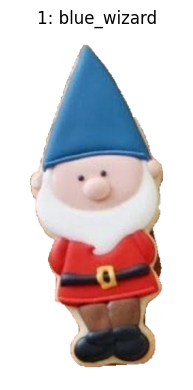

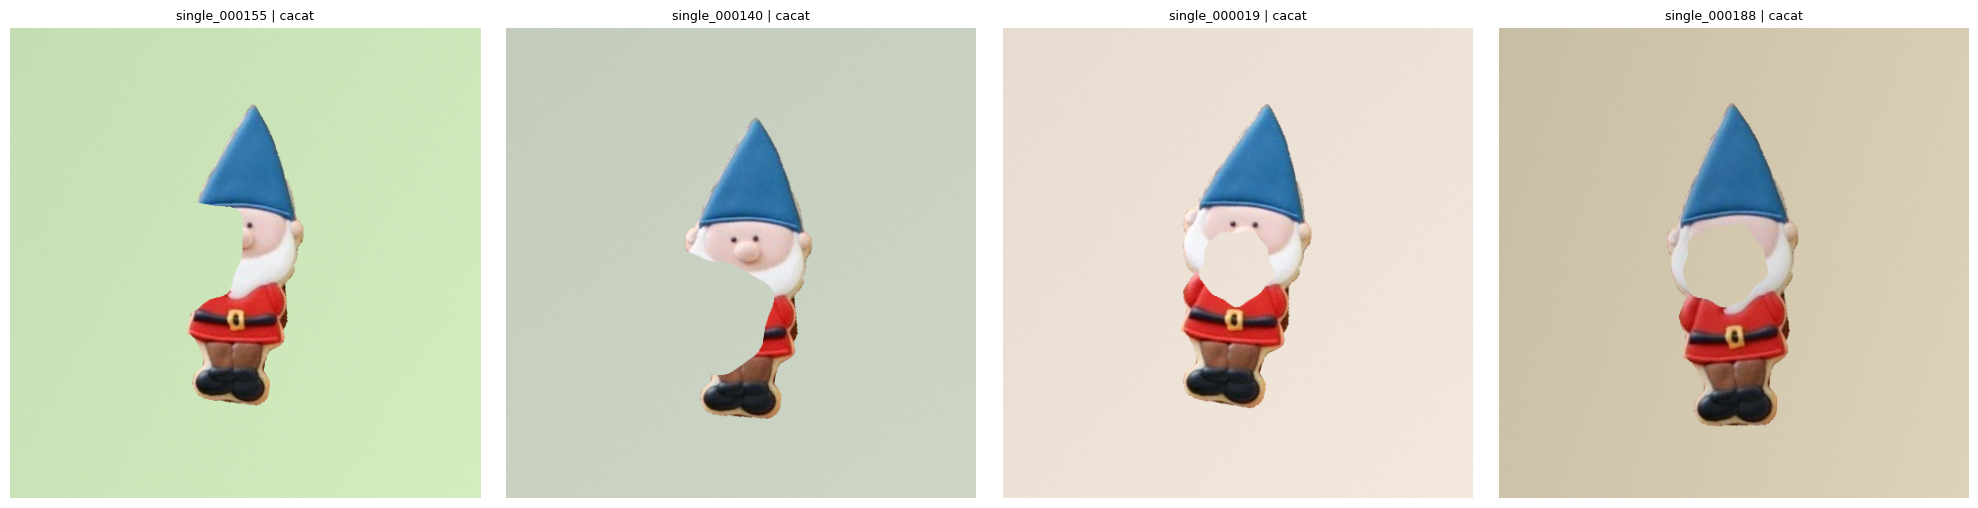

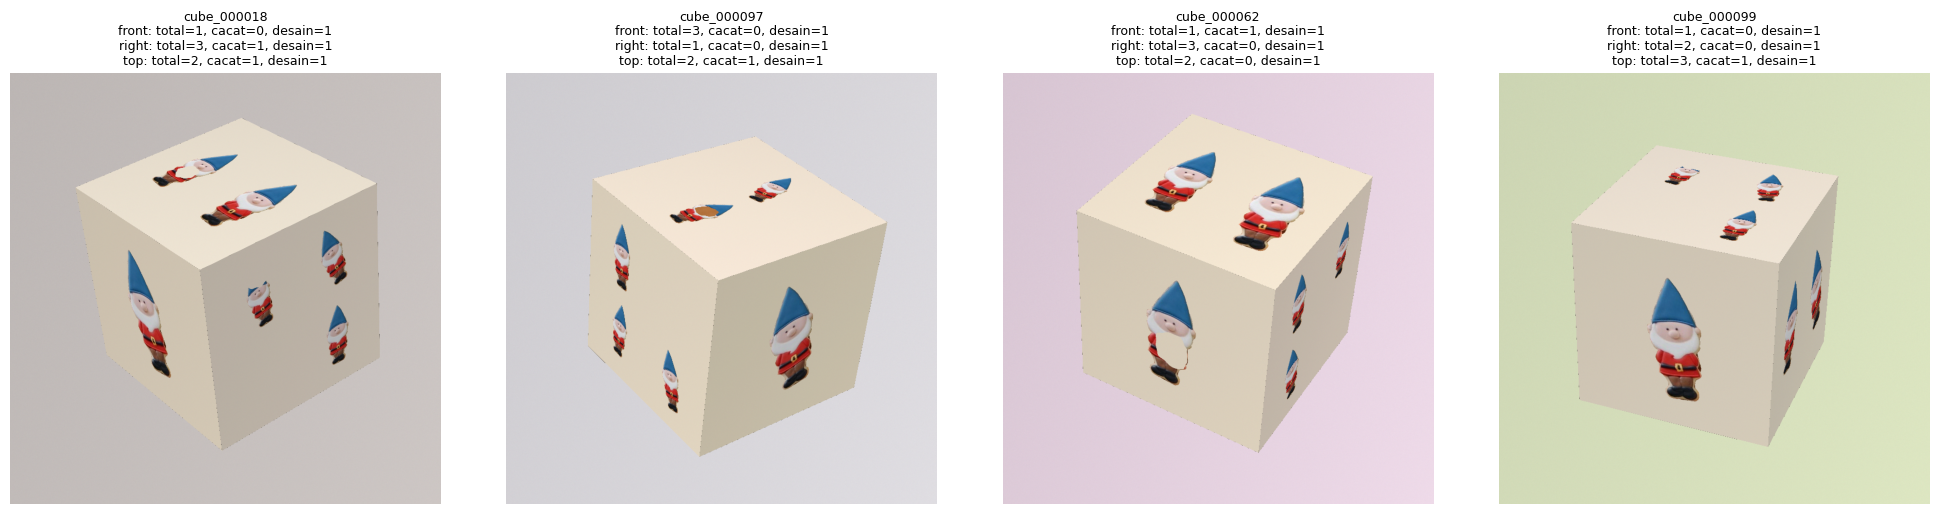

In [4]:
fig, axes = plt.subplots(1, len(references), figsize=(3*len(references),4), squeeze=False)
for ax, (design_id, ref) in zip(axes.ravel(), references.items()):
    ax.imshow(ref['rgba']); ax.set_title(f"{design_id}: {ref['name']}"); ax.axis('off')
plt.tight_layout(); plt.show()

def visualize_samples(index, labels=None, n=4, split='train'):
    subset = index[index['split'].eq(split)]
    if subset.empty:
        print(f'Tidak ada citra pada split {split}.'); return
    subset = subset.sample(min(n,len(subset)), random_state=SEED)
    fig, axes = plt.subplots(1,len(subset),figsize=(5*len(subset),5),squeeze=False)
    targets = {} if labels is None else labels.set_index('image_id').to_dict('index')
    for ax, row in zip(axes.ravel(), subset.itertuples()):
        ax.imshow(read_rgb(row.image_path)); ax.axis('off')
        title = row.image_id
        y = targets.get(row.image_id)
        if y is not None:
            if row.task == 'single':
                title += ' | cacat' if y['is_defective'] else ' | sempurna'
            else:
                title += '\n' + '\n'.join(f"{f}: total={y[f+'_total']}, cacat={y[f+'_defective']}, desain={y[f+'_design_count']}" for f in FACES)
        ax.set_title(title,fontsize=9)
    plt.tight_layout(); plt.show()

visualize_samples(single_index, single_labels)
visualize_samples(cube_index, cube_labels)

## 5. Data untuk pengembangan
Gunakan `train` untuk melatih metode dan `val` untuk memilih parameter/threshold. Gunakan `test` untuk evaluasi akhir. Jangan mengubah split berdasarkan hasil uji. Dataset satu desain belum cukup untuk menguji penghitungan desain unik.

Dataframe di bawah menyimpan path citra dan target. Muat citra sesuai kebutuhan agar penggunaan RAM terkontrol. Anotasi tambahan tersedia di folder `annotations` dan `masks`; tidak boleh digunakan sebagai masukan saat inferensi.

In [5]:
def labeled_split(index, labels, split):
    images = index[index['split'].eq(split)].copy()
    if labels is None:
        raise ValueError('Dataset ini tidak memiliki label.')
    out = images.merge(labels.drop(columns=['split','image'],errors='ignore'), on='image_id', how='left', validate='one_to_one', indicator=True)
    if not out['_merge'].eq('both').all():
        raise ValueError('Ada citra yang tidak memiliki label.')
    return out.drop(columns='_merge')

single_train = labeled_split(single_index, single_labels, 'train') if single_labels is not None else None
single_val = labeled_split(single_index, single_labels, 'val') if single_labels is not None else None
cube_train = labeled_split(cube_index, cube_labels, 'train') if cube_labels is not None else None
cube_val = labeled_split(cube_index, cube_labels, 'val') if cube_labels is not None else None
# Contoh akses: image = read_rgb(single_train.iloc[0].image_path)
# TODO: ekstraksi fitur, augmentasi train, DataLoader, pelatihan, dan pemilihan parameter.
# Terapkan transformasi geometri secara konsisten pada citra dan label spasial bila digunakan.

## 6. Validasi prediksi dan evaluasi

In [6]:
def validate_predictions(pred, expected_ids, task, leaderboard=False):
    cols = SINGLE_COLS if task == 'single' else cube_columns(leaderboard)
    if list(pred.columns) != cols:
        raise ValueError(f'Nama/urutan kolom wajib: {cols}')
    if pred.image_id.isna().any() or pred.image_id.duplicated().any():
        raise ValueError('ID kosong atau duplikat.')
    if set(pred.image_id) != set(expected_ids) or len(pred) != len(expected_ids):
        raise ValueError('ID hilang atau berlebih dibanding daftar citra.')
    values = pred[cols[1:]].to_numpy(dtype=float)
    if not np.isfinite(values).all():
        raise ValueError('Prediksi memuat NaN/inf.')
    if task == 'single':
        if not pred.is_defective.isin([0,1]).all() or not pred.defect_score.between(0,1).all():
            raise ValueError('Label harus 0/1; defect_score harus 0–1.')
    else:
        if (values < 0).any() or not np.equal(values,np.floor(values)).all():
            raise ValueError('Hitungan wajib integer nonnegatif.')
        for f in FACES:
            if (pred[f+'_defective'] > pred[f+'_total']).any():
                raise ValueError('Jumlah cacat melebihi jumlah total.')
            if leaderboard:
                d,t = pred[f+'_design_count'],pred[f+'_total']
                if ((d>t)|(d>len(references))|((t>0)&(d==0))).any():
                    raise ValueError('Jumlah desain unik tidak konsisten.')
    return pred

def aligned_targets(pred, truth, cols):
    if truth is None:
        raise ValueError('Evaluasi tidak tersedia: hidden dataset tidak memiliki label.')
    if truth.image_id.duplicated().any():
        raise ValueError('ID ground truth duplikat.')
    indexed = truth.set_index('image_id')
    missing = set(pred.image_id)-set(indexed.index)
    if missing:
        raise ValueError(f'Ground truth tidak tersedia untuk {len(missing)} citra.')
    return indexed.loc[pred.image_id,cols].to_numpy(dtype=float)

def evaluate_single(pred, truth):
    y = aligned_targets(pred, truth, ['is_defective']).ravel().astype(int)
    p = pred.is_defective.to_numpy(dtype=int)
    return {'precision':precision_score(y,p,zero_division=0),
            'recall':recall_score(y,p,zero_division=0),
            'f1':f1_score(y,p,zero_division=0),
            'balanced_accuracy':balanced_accuracy_score(y,p) if len(np.unique(y))==2 else np.nan,
            'confusion_matrix_labels_0_1':confusion_matrix(y,p,labels=[0,1]).tolist()}

def evaluate_cube(pred, truth, leaderboard=False):
    fields = ['total','defective'] + (['design_count'] if leaderboard else [])
    cols = cube_columns(leaderboard)[1:]
    y = aligned_targets(pred,truth,cols)
    p = pred[cols].to_numpy(dtype=float)
    if len(p)==0:
        raise ValueError('Tidak ada prediksi untuk dievaluasi.')
    # Kolom diurutkan field dahulu, lalu face: N × K × 3.
    errors = np.abs(p-y).reshape(len(p),len(fields),3)
    result = {}
    for k, field in enumerate(fields):
        result['mae_'+field] = float(errors[:,k,:].mean())
        for j, face in enumerate(FACES):
            result[f'mae_{face}_{field}'] = float(errors[:,k,j].mean())
    result['exact_match_face_pct'] = float((errors==0).all(axis=1).mean()*100)
    result['exact_match_image_pct'] = float((errors==0).all(axis=(1,2)).mean()*100)
    bad_truth = y.reshape(len(p),len(fields),3)[:,1,:]
    positive = bad_truth > 0
    result['mae_defective_on_defective_faces'] = float(errors[:,1,:][positive].mean()) if positive.any() else None
    return result

MAE dihitung terpisah untuk setiap target dengan rata-rata seluruh citra dan sisi. Exact match tugas utama memeriksa 2 nilai per sisi atau 6 nilai per citra. Pada leaderboard, masing-masing menjadi 3 dan 9 nilai. Metrik peringkat leaderboard belum ditetapkan; fungsi ini tidak mengasumsikan skor gabungan.

MAE cacat pada sisi yang memang cacat membantu memeriksa apakah metode hanya memprediksi nol. Balanced accuracy dilaporkan NaN apabila data evaluasi hanya memuat satu kelas.

## 7. Tugas 1 — pendekatan non-deep learning
**Ide:** (1) cocokkan citra ke setiap desain referensi dengan **SIFT + rasio Lowe + RANSAC homografi** (desain dengan inlier terbanyak = desain produk; ini sekaligus menangani rotasi, skala, dan perspektif); (2) **warp referensi ke citra**, samakan warna/pencahayaan secara robust; (3) hitung **peta selisih toleran** `T(p) = min_s ΔE(I(p+s), R(p))` — pergeseran hanya pada sisi citra sehingga salah-sejajar kecil diabaikan, tetapi bagian/hiasan yang hilang tetap terdeteksi; (4) ringkas peta menjadi fitur (luas komponen terhubung terbesar, pita tepi vs bagian dalam, hiasan yang hilang, kualitas penyelarasan) dan (5) klasifikator klasik + **threshold dari validasi (balanced accuracy)**.

Fitur dinormalisasi terhadap luas objek di referensi, bukan terhadap ID desain, supaya mudah digeneralisasi dari 1 ke 7 desain. Pada saat inferensi hanya citra RGB dan gambar referensi yang dipakai.

In [7]:
import cv2, re, time, os
from scipy import ndimage as ndi
from concurrent.futures import ThreadPoolExecutor
try:
    from tqdm.auto import tqdm
except Exception:
    def tqdm(x, **kwargs): return x
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score

# ---- Path seragam lokal & Google Colab (Drive /content) ----
_tpl_path = _resolve_existing_path(
    '',
    ['template_all'],
    [
        '/content/drive/MyDrive/Comvis/Mini_Project/template_all',
        '/content/drive/MyDrive/COMVIS/Mini_Project/template_all',
        '/content/template_all',
    ],
)
TEMPLATE_DIR = str(_tpl_path) if _tpl_path is not None else ''      # folder template_all (7 gambar desain gnome). Kosong = pakai references/ dari ZIP training
TEMPLATE_ID_MAP = {}   # opsional: {'nama_file_tanpa_ekstensi': design_id} bila ID dari nama file salah

_hid_zip_path = _resolve_existing_path(
    '',
    ['data/hidden_students.zip'],
    [
        '/content/drive/MyDrive/Comvis/Mini_Project/data/hidden_students.zip',
        '/content/drive/MyDrive/COMVIS/Mini_Project/data/hidden_students.zip',
        '/content/hidden_students.zip',
        '/content/data/hidden_students.zip',
    ],
)
HIDDEN_ZIP = str(_hid_zip_path) if _hid_zip_path is not None else ''        # path hidden_students.zip (otomatis terdeteksi dari data/ atau unduhan gdown)
HIDDEN_DIR = ''        # folder hasil ekstrak hidden_students.zip bila sudah diekstrak manual
HIDDEN_URL = 'https://drive.google.com/file/d/1Jkl9WL75xv_Gxb24kaDKE48Q1q6iYFYJ/view?usp=sharing'

FEAT_VERSION = 'v1'
N_WORKERS = 4
P = dict(
    img_side=800,      # sisi terpanjang citra setelah di-resize (tidak pernah di-upscale)
    ref_side=512,      # sisi terpanjang referensi
    ref_blur=1.2,      # blur referensi sebelum di-warp
    sift_n=4000, sift_contrast=0.02,
    ratio=0.78, ransac_px=4.0, min_inliers=12,      # percobaan 1
    ratio2=0.85, ransac_px2=6.0, min_inliers2=8,    # percobaan 2 (lebih longgar)
    refine_ratio=0.90, refine_px=3.0,
    blur=1.0,          # blur citra sebelum membandingkan
    shift_frac=0.01,   # radius toleransi geser = shift_frac*sqrt(luas objek), dibatasi 1..3 px
    wL=0.75,           # bobot selisih kecerahan (L) terhadap kromatik (a,b)
    taus=(12, 18, 26, 38), tau_key=26,               # ambang selisih warna (Delta-E)
    icing_de=18.0,     # piksel referensi yang beda >= ini dari warna dasar dianggap 'hiasan/fitur'
)
print('Konfigurasi non-DL siap. OpenCV', cv2.__version__)

Konfigurasi non-DL siap. OpenCV 4.13.0


In [8]:
# === Memuat referensi (template_all / references) dan membangun "bank" fitur referensi ===
IMG_EXT = {'.png', '.jpg', '.jpeg', '.webp', '.bmp'}

def auto_alpha(rgb):
    """Mask objek untuk gambar tanpa alpha: latar = area mirip warna tepi yang terhubung ke tepi."""
    lab = cv2.cvtColor(rgb.astype(np.float32)/255.0, cv2.COLOR_RGB2LAB)
    border = np.concatenate([lab[0], lab[-1], lab[:, 0], lab[:, -1]])
    d = np.linalg.norm(lab - np.median(border, axis=0), axis=2)
    thr, _ = cv2.threshold(np.clip(d*4, 0, 255).astype(np.uint8), 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    fg = (d > max(thr/4.0, 6.0)).astype(np.uint8)
    fg = cv2.morphologyEx(fg, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    lab_bg, _ = ndi.label(fg == 0)
    edge_ids = set(np.unique(np.r_[lab_bg[0], lab_bg[-1], lab_bg[:, 0], lab_bg[:, -1]])) - {0}
    fg = ~np.isin(lab_bg, list(edge_ids))
    lab_fg, n = ndi.label(fg)
    if n > 1:
        sizes = ndi.sum(fg, lab_fg, range(1, n+1))
        fg = lab_fg == (1 + int(np.argmax(sizes)))
    return (fg*255).astype(np.uint8)

def to_rgba(path):
    with Image.open(path) as im:
        rgba = np.asarray(im.convert('RGBA')).copy()
    if rgba[..., 3].min() > 250:
        rgba[..., 3] = auto_alpha(rgba[..., :3])
    return rgba

def load_template_all(folder, id_map=None):
    """Keluaran sama dengan load_references(): {design_id: {'name','rgba','mask'}}."""
    folder, id_map, refs = Path(folder), (id_map or {}), {}
    dj = next(iter(sorted(folder.rglob('designs.json'))), None)
    if dj is not None:
        for item in json.loads(dj.read_text()):
            name = Path(item['reference_file']).name
            path = next((p for p in [dj.parent/item['reference_file'], dj.parent/'references'/item['reference_file']] if p.exists()),
                        next(iter(folder.rglob(name)), None))
            rgba = to_rgba(path)
            refs[int(item['design_id'])] = {'name': item['name'], 'rgba': rgba, 'mask': rgba[..., 3] > 0}
    else:
        files = sorted(p for p in folder.rglob('*') if p.suffix.lower() in IMG_EXT
                       and 'mask' not in p.stem.lower() and not p.name.startswith('.'))
        ids = {}
        for i, p in enumerate(files, 1):
            nums = re.findall(r'\d+', p.stem)
            ids[p] = int(id_map[p.stem]) if p.stem in id_map else (int(nums[-1]) if nums else i)
        if len(set(ids.values())) != len(files):
            ids = {p: i for i, p in enumerate(files, 1)}
        for p, did in ids.items():
            rgba = to_rgba(p)
            refs[did] = {'name': p.stem, 'rgba': rgba, 'mask': rgba[..., 3] > 0}
    if not refs:
        raise ValueError(f'Tidak ada gambar template di {folder}')
    return dict(sorted(refs.items()))

def build_bank(refs):
    """Siapkan tiap referensi: crop, resize, warna ter-blur, keypoint SIFT, dan mask 'hiasan'."""
    bank = {}
    for did, item in refs.items():
        rgba = item['rgba']
        a = rgba[..., 3] >= 128
        ys, xs = np.where(a)
        rgb = rgba[ys.min():ys.max()+1, xs.min():xs.max()+1, :3]
        alpha = a[ys.min():ys.max()+1, xs.min():xs.max()+1].astype(np.uint8)*255
        pad = 6
        rgb = cv2.copyMakeBorder(rgb, pad, pad, pad, pad, cv2.BORDER_CONSTANT, value=0)
        alpha = cv2.copyMakeBorder(alpha, pad, pad, pad, pad, cv2.BORDER_CONSTANT, value=0)
        s = P['ref_side']/max(rgb.shape[:2])
        size = (max(8, round(rgb.shape[1]*s)), max(8, round(rgb.shape[0]*s)))
        rgb = cv2.resize(rgb, size, interpolation=cv2.INTER_AREA if s < 1 else cv2.INTER_CUBIC)
        alpha = (cv2.resize(alpha, size, interpolation=cv2.INTER_LINEAR) >= 128).astype(np.uint8)*255
        af = (alpha > 0).astype(np.float32)
        num = cv2.GaussianBlur(rgb.astype(np.float32)*af[..., None], (0, 0), P['ref_blur'])
        den = cv2.GaussianBlur(af, (0, 0), P['ref_blur'])[..., None]
        rgb_b = np.where(den > 1e-3, num/np.maximum(den, 1e-3), 0).astype(np.float32)
        gray = prep_gray(rgb)
        sift = cv2.SIFT_create(nfeatures=P['sift_n'], contrastThreshold=P['sift_contrast'], edgeThreshold=12)
        kp, desc = sift.detectAndCompute(gray, cv2.dilate(alpha, np.ones((3, 3), np.uint8)))
        lab = cv2.cvtColor(rgb.astype(np.float32)/255.0, cv2.COLOR_RGB2LAB)
        core = cv2.erode(alpha, np.ones((5, 5), np.uint8)) > 0
        base = np.median(lab[core], axis=0)
        feat = (np.linalg.norm(lab - base, axis=2) > P['icing_de']) & core
        bank[did] = dict(name=item['name'], rgb=rgb, rgb_b=rgb_b, alpha_u8=alpha, area=int((alpha > 0).sum()),
                         pts=np.float32([k.pt for k in kp]), desc=desc,
                         feat_u8=feat.astype(np.uint8)*255, n_kp=len(kp))
    return bank

_BANK_CACHE = {}
def get_bank(refs):
    key = tuple((k, v['name'], v['rgba'].shape, int(v['rgba'][..., 3].sum())) for k, v in sorted(refs.items()))
    if key not in _BANK_CACHE:
        _BANK_CACHE[key] = build_bank(refs)
    return _BANK_CACHE[key]


In [9]:
# === Penyelarasan (SIFT + RANSAC homografi) dan fitur selisih terhadap referensi ===
def prep_gray(rgb):
    return cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY))

def resize_max(rgb, side):
    h, w = rgb.shape[:2]
    s = side/max(h, w)
    if s >= 1: return rgb, 1.0
    return cv2.resize(rgb, (round(w*s), round(h*s)), interpolation=cv2.INTER_AREA), s

def image_keypoints(img):
    sift = cv2.SIFT_create(nfeatures=P['sift_n'], contrastThreshold=P['sift_contrast'], edgeThreshold=12)
    kp, desc = sift.detectAndCompute(prep_gray(img), None)
    if desc is None or len(kp) < 8: return np.zeros((0, 2), np.float32), None
    return np.float32([k.pt for k in kp]), desc

def sane_h(H, ref, shape):
    h, w = shape
    ph, pw = ref['rgb'].shape[:2]
    q = cv2.perspectiveTransform(np.float32([[0, 0], [pw, 0], [pw, ph], [0, ph]]).reshape(-1, 1, 2), H)
    if not np.isfinite(q).all() or not cv2.isContourConvex(q.astype(np.float32)): return False
    return 0.005*h*w < cv2.contourArea(q.astype(np.float32)) < 4.0*h*w

def fit_design(ref, pts, knn, ratio, thr, shape):
    """RANSAC pada pasangan lolos uji rasio Lowe (satu-ke-satu); lalu refine kuadrat-terkecil pada pasangan konsisten."""
    good = [m[0] for m in knn if len(m) == 2 and m[0].distance < ratio*m[1].distance]
    best_by_train = {}
    for m in good:                                   # satu keypoint citra hanya boleh dipakai sekali
        if m.trainIdx not in best_by_train or m.distance < best_by_train[m.trainIdx].distance: best_by_train[m.trainIdx] = m
    good = list(best_by_train.values())
    out = dict(H=None, inl=0, n_good=len(good), rmse=np.nan, n_cons=0)
    if len(good) < 6: return out
    src = ref['pts'][[m.queryIdx for m in good]]; dst = pts[[m.trainIdx for m in good]]
    live = np.ones(len(good), bool); H = None
    for _ in range(3):                               # homografi degeneratif (runtuh ke satu titik) -> buang inlier-nya, ulangi
        if live.sum() < 6: break
        Hc, msk = cv2.findHomography(src[live], dst[live], cv2.RANSAC, thr, maxIters=4000, confidence=0.995)
        if Hc is None: break
        if sane_h(Hc, ref, shape):
            H = Hc; break
        sub = np.flatnonzero(live); live[sub[msk.ravel().astype(bool)]] = False
    if H is None: return out
    pr = cv2.perspectiveTransform(src.reshape(-1, 1, 2), H).reshape(-1, 2)
    out.update(H=H, inl=int((np.linalg.norm(pr - dst, axis=1) < thr).sum()))
    cand = [m[0] for m in knn if len(m) == 2 and m[0].distance < P['refine_ratio']*m[1].distance]
    cs = ref['pts'][[m.queryIdx for m in cand]]; cd = pts[[m.trainIdx for m in cand]]
    err = np.linalg.norm(cv2.perspectiveTransform(cs.reshape(-1, 1, 2), H).reshape(-1, 2) - cd, axis=1)
    keep = err < P['refine_px']
    out.update(n_cons=int(keep.sum()), rmse=float(np.sqrt(np.mean(err[keep]**2))) if keep.any() else np.nan)
    if keep.sum() >= 10:
        H2, _ = cv2.findHomography(cs[keep], cd[keep], 0)
        if H2 is not None and sane_h(H2, ref, shape):
            e2 = np.linalg.norm(cv2.perspectiveTransform(cs[keep].reshape(-1, 1, 2), H2).reshape(-1, 2) - cd[keep], axis=1)
            out.update(H=H2, rmse=float(np.sqrt(np.mean(e2**2))))
    return out

def align_image(pts, desc, shape, bank):
    """Cocokkan citra ke semua desain referensi. Keluaran: daftar kandidat (inlier terbanyak dulu); kandidat yang
    inliernya >= 60% dari terbaik dipertahankan agar desain yang mirip bisa dibedakan lewat kecocokan fotometrik."""
    if desc is None: return []
    bf = cv2.BFMatcher(cv2.NORM_L2)
    knn = {d: bf.knnMatch(ref['desc'], desc, k=2) for d, ref in bank.items() if ref['desc'] is not None}
    for ratio, thr, min_inl in [(P['ratio'], P['ransac_px'], P['min_inliers']),
                                (P['ratio2'], P['ransac_px2'], P['min_inliers2'])]:
        fits = {d: fit_design(bank[d], pts, knn[d], ratio, thr, shape) for d in knn}
        order = sorted(fits, key=lambda d: fits[d]['inl'], reverse=True)
        if order and fits[order[0]]['inl'] >= min_inl and fits[order[0]]['H'] is not None:
            top = fits[order[0]]['inl']
            second = fits[order[1]]['inl'] if len(order) > 1 else 0
            return [dict(design=d, margin=(top-second)/max(top, 1), **fits[d]) for d in order[:3]
                    if fits[d]['H'] is not None and fits[d]['inl'] >= max(min_inl, 0.6*top)]
    return []

# ---------- fotometri ----------
def fit_photometric(Rl, Il, W, rng):
    """Samakan warna referensi ke citra (Lab) dengan regresi robust (IRLS) pada piksel dalam objek."""
    out = Rl.copy()
    idx = np.flatnonzero(W.ravel())
    if len(idx) > 30000: idx = rng.choice(idx, 30000, replace=False)
    for c, (lo, hi) in enumerate([(0.5, 2.0), (0.6, 1.6), (0.6, 1.6)]):
        x = Rl[..., c].ravel()[idx]; y = Il[..., c].ravel()[idx]
        a, b = 1.0, float(np.median(y-x))
        for _ in range(5):
            res = y - (a*x + b)
            mad = 1.4826*np.median(np.abs(res - np.median(res))) + 0.5
            wt = 1.0/(1.0 + (res/(2.0*mad))**2)
            sw = wt.sum(); mx = (wt*x).sum()/sw; my = (wt*y).sum()/sw
            a = float(np.clip(((wt*(x-mx)*(y-my)).sum()/sw)/((wt*(x-mx)**2).sum()/sw + 1e-6), lo, hi))
            b = my - a*mx
        out[..., c] = a*Rl[..., c] + b
    return out

def tolerant_diff(Il, Rl, r, wL):
    """T(p) = min_{|s|<=r} dE(I(p+s), R(p)). Pergeseran diterapkan pada CITRA: hiasan/bagian yang hilang
    tetap terdeteksi, sedangkan salah-sejajar kecil (sliver di tepi) tidak."""
    best = np.full(Il.shape[:2], np.inf, np.float32)
    wts = np.float32([wL, 1, 1])
    for dy in range(-r, r+1):
        for dx in range(-r, r+1):
            if dx*dx + dy*dy > r*r + 1: continue
            d = np.sqrt((((np.roll(Il, (dy, dx), axis=(0, 1)) - Rl)*wts)**2).sum(-1))
            np.minimum(best, d, out=best)
    return best

def lowfreq_field(Rl, Il, good, sigma):
    """Koreksi iluminasi yang berubah pelan (gradien cahaya) memakai konvolusi ternormalisasi."""
    w = good.astype(np.float32)
    num = cv2.GaussianBlur((Il-Rl)*w[..., None], (0, 0), sigma)
    den = cv2.GaussianBlur(w, (0, 0), sigma)[..., None]
    return np.where(den > 0.05, num/np.maximum(den, 1e-3), 0).astype(np.float32)

def largest_cc(b):
    if not b.any(): return 0
    n, _, st, _ = cv2.connectedComponentsWithStats(b.astype(np.uint8), connectivity=8)
    return int(st[1:, cv2.CC_STAT_AREA].max()) if n > 1 else 0

DIFF_KEYS = (['T_med', 'T_p90', 'T_p99', 'T_blur_max', 'band_frac', 'int_frac', 'int_maxcc', 'band_maxcc',
              'icing_area', 'icing_missing', 'icing_maxcc', 'scale', 'in_img']
             + [f'{k}_{t}' for t in P['taus'] for k in ('frac', 'maxcc', 'ncc')])
ALIGN_KEYS = ['align_ok', 'n_good', 'n_inliers', 'inlier_ratio', 'n_consistent', 'rmse', 'margin']
FEATURE_COLS = ALIGN_KEYS + DIFF_KEYS

def diff_features(img, H, ref, debug=False):
    h, w = img.shape[:2]
    warp = lambda src, interp=cv2.INTER_LINEAR: cv2.warpPerspective(src, H, (w, h), flags=interp)
    A = warp(ref['alpha_u8']) >= 128
    area = int(A.sum())
    if area < 400: return None, None
    sq = np.sqrt(area)
    r = int(np.clip(round(P['shift_frac']*sq), 1, 3))
    ys, xs = np.where(A); pad = r + 3 + int(0.02*sq)
    y0, y1 = max(ys.min()-pad, 0), min(ys.max()+pad+1, h); x0, x1 = max(xs.min()-pad, 0), min(xs.max()+pad+1, w)
    sl = (slice(y0, y1), slice(x0, x1))
    A = A[sl]; Fm = (warp(ref['feat_u8']) >= 128)[sl]
    Rrgb = warp(ref['rgb_b'])[sl]
    I = cv2.GaussianBlur(img[sl], (0, 0), P['blur']).astype(np.float32)/255.0
    Il = cv2.cvtColor(I, cv2.COLOR_RGB2LAB)
    Rl = cv2.cvtColor(np.clip(Rrgb, 0, 255)/255.0, cv2.COLOR_RGB2LAB)
    k = max(3, int(0.04*sq)) | 1
    W = cv2.erode(A.astype(np.uint8), np.ones((k, k), np.uint8)) > 0
    if W.sum() < 200: W = A
    rng = np.random.default_rng(0)
    Rl = fit_photometric(Rl, Il, W, rng)
    T0 = tolerant_diff(Il, Rl, 1, P['wL'])
    Rl = Rl + lowfreq_field(Rl, Il, W & (T0 < 18), max(6.0, 0.08*sq))
    T = tolerant_diff(Il, Rl, r, P['wL'])
    Ts = np.where(A, cv2.medianBlur(T.astype(np.float32), 3), 0).astype(np.float32)
    f = {}
    Tm = Ts[A]
    f.update(T_med=float(np.median(Tm)), T_p90=float(np.percentile(Tm, 90)), T_p99=float(np.percentile(Tm, 99)))
    kb = max(5, int(0.05*sq)) | 1
    f['T_blur_max'] = float(cv2.boxFilter(Ts, -1, (kb, kb)).max())
    for t in P['taus']:
        b = (Ts > t) & A
        f[f'frac_{t}'] = float(b.sum()/area); f[f'maxcc_{t}'] = largest_cc(b)/area
        n, _, st, _ = cv2.connectedComponentsWithStats(b.astype(np.uint8), connectivity=8)
        f[f'ncc_{t}'] = float((st[1:, cv2.CC_STAT_AREA] >= 0.002*area).sum()) if n > 1 else 0.0
    bk = (Ts > P['tau_key']) & A
    dt = ndi.distance_transform_edt(A)
    band = A & (dt <= 0.05*sq)
    f.update(band_frac=float((bk & band).sum()/area), int_frac=float((bk & ~band).sum()/area),
             band_maxcc=largest_cc(bk & band)/area, int_maxcc=largest_cc(bk & ~band)/area)
    fa = int(Fm.sum()); fb = (Ts > 22) & Fm
    f.update(icing_area=fa/area, icing_missing=float(fb.sum()/max(fa, 1)), icing_maxcc=largest_cc(fb)/area)
    ph, pw = ref['rgb'].shape[:2]
    f['scale'] = float(np.sqrt(area/ref['area']))
    q = cv2.perspectiveTransform(np.float32([[0, 0], [pw, 0], [pw, ph], [0, ph]]).reshape(-1, 1, 2), H)
    f['in_img'] = float(min(1.0, area/max(cv2.contourArea(q.astype(np.float32))*ref['area']/(ph*pw), 1.0)))
    dbg = dict(img=img, box=(y0, y1, x0, x1), A=A, Ts=Ts, Rrgb=Rrgb, quad=q.reshape(-1, 2), mask=bk) if debug else None
    return f, dbg

def analyze_image(rgb, bank, debug=False):
    t0 = time.time()
    img, _ = resize_max(rgb, P['img_side'])
    pts, desc = image_keypoints(img)
    feats = {k: np.nan for k in FEATURE_COLS}
    feats.update(align_ok=0, design_id=-1, t_ms=0.0)
    best = None
    for al in align_image(pts, desc, img.shape[:2], bank):
        d, dbg = diff_features(img, al['H'], bank[al['design']], debug)
        # desain yang benar = yang paling cocok secara fotometrik (median selisih terkecil; cacat < 50% luas)
        if d is not None and (best is None or d['T_med'] < best[0]['T_med'] - 1e-6):
            best = (d, dbg, al)
    if best is not None:
        d, dbg, al = best
        feats.update(d)
        feats.update(align_ok=1, design_id=int(al['design']), n_good=al['n_good'], n_inliers=al['inl'],
                     inlier_ratio=al['inl']/max(al['n_good'], 1), n_consistent=al['n_cons'],
                     rmse=al['rmse'], margin=al['margin'])
        if dbg is not None: dbg['design'] = al['design']; dbg['H'] = al['H']
    else:
        dbg = None
    feats['t_ms'] = (time.time()-t0)*1000
    return feats, dbg


Referensi dari template_all: {1: 'blue_wizard', 2: 'brown_hat_gnome', 3: 'green_hat_elf', 4: 'pilgrim', 5: 'santa', 6: 'striped_hat_elf', 7: 'witch'}


{1: '600 keypoint', 2: '1227 keypoint', 3: '786 keypoint', 4: '1001 keypoint', 5: '849 keypoint', 6: '952 keypoint', 7: '1193 keypoint'}


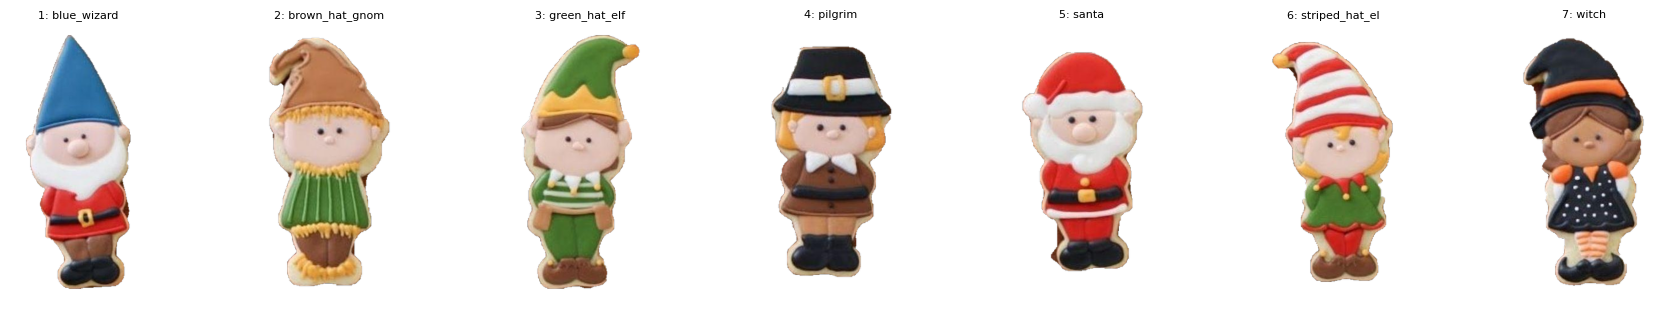

In [10]:
# === Referensi yang dipakai pipeline non-DL ===
# Pakai template_all (7 desain) bila diisi; jika kosong, pakai references/ dari ZIP training.
if TEMPLATE_DIR:
    REFS = load_template_all(TEMPLATE_DIR, TEMPLATE_ID_MAP)
    print('Referensi dari template_all:', {k: v['name'] for k, v in REFS.items()})
else:
    REFS = references
    print('TEMPLATE_DIR kosong -> memakai references/ dari ZIP training:', {k: v['name'] for k, v in REFS.items()})
BANK = build_bank(REFS)
print({d: f"{b['n_kp']} keypoint" for d, b in BANK.items()})
fig, axes = plt.subplots(1, len(REFS), figsize=(2.6*len(REFS), 3.2), squeeze=False)
for ax, (d, item) in zip(axes.ravel(), REFS.items()):
    ax.imshow(item['rgba']); ax.set_title(f"{d}: {item['name'][:14]}", fontsize=8); ax.axis('off')
plt.tight_layout(); plt.show()


### Visualisasi penyelarasan dan peta selisih

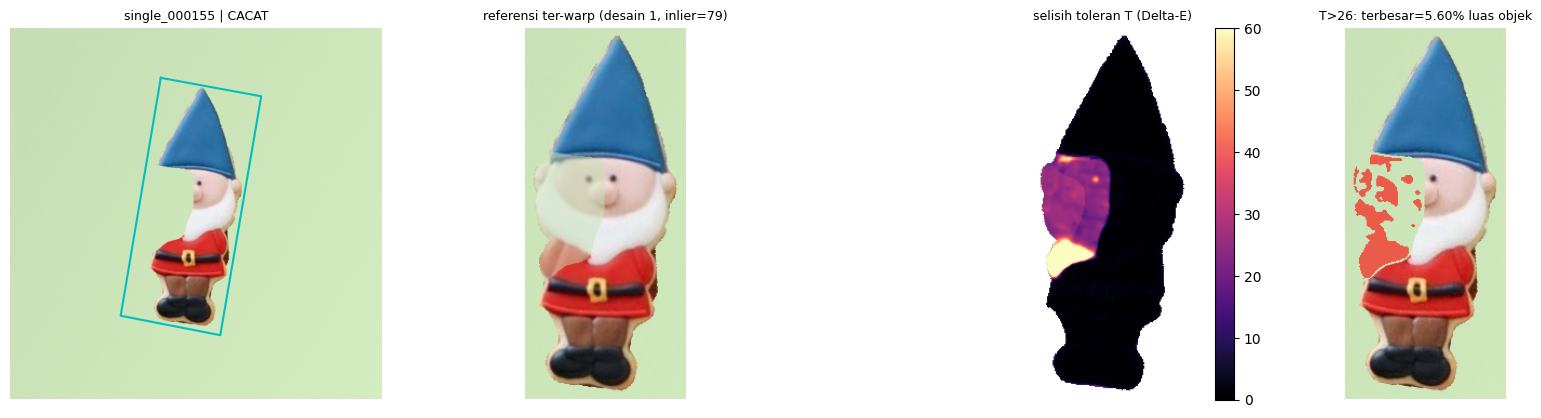

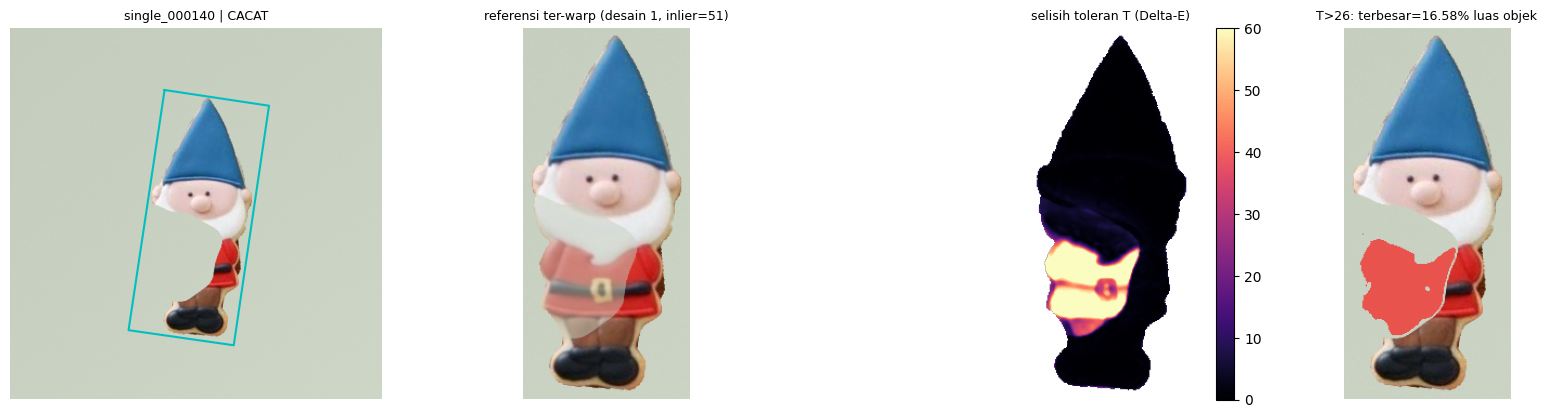

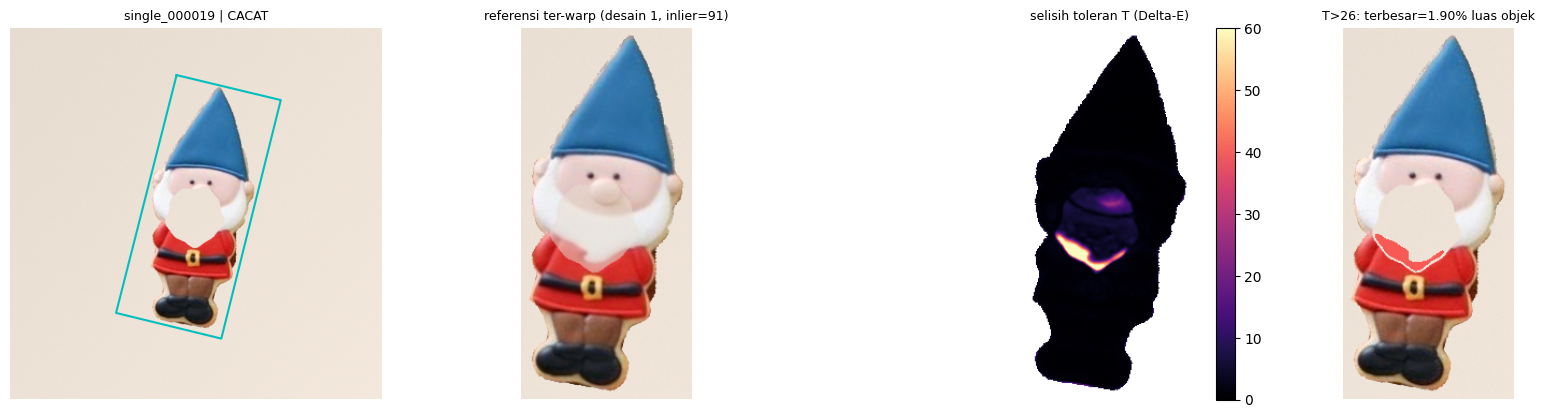

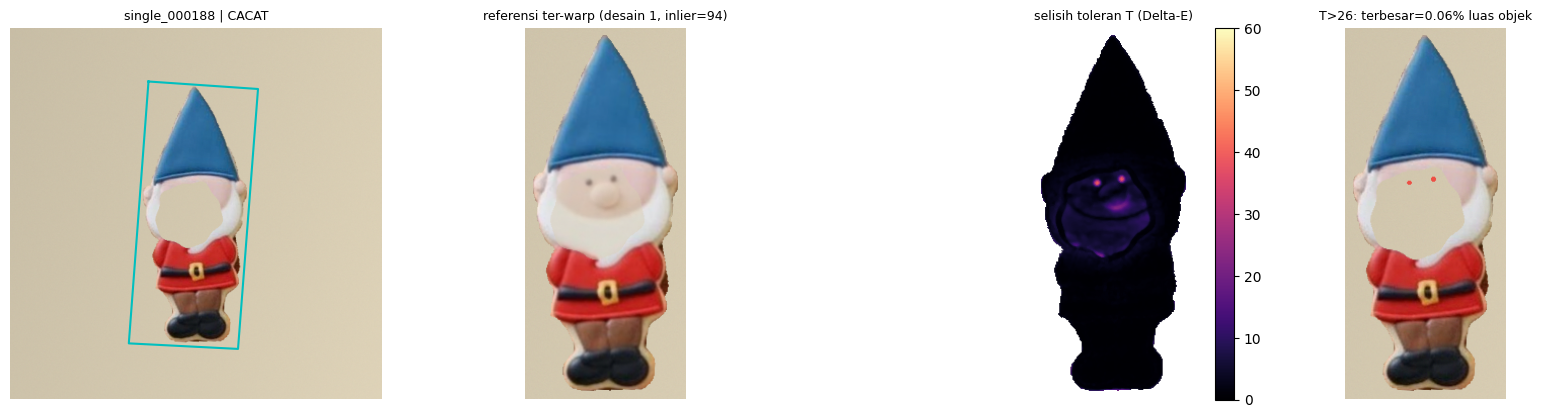

In [11]:
# === Visualisasi penyelarasan & peta selisih (untuk memahami metode dan analisis kesalahan) ===
def show_debug(rgb, title=''):
    feats, dbg = analyze_image(rgb, BANK, debug=True)
    fig, ax = plt.subplots(1, 4, figsize=(17, 4.2))
    ax[0].imshow(rgb if dbg is None else dbg['img']); ax[0].set_title(title, fontsize=9)
    if dbg is None:
        for a in ax[1:]: a.axis('off')
        ax[0].axis('off'); ax[1].text(0.1, 0.5, 'penyelarasan gagal', transform=ax[1].transAxes); plt.show(); return feats
    y0, y1, x0, x1 = dbg['box']; q = dbg['quad']
    ax[0].plot(*np.r_[q, q[:1]].T, 'c-', lw=1.5); ax[0].axis('off')
    crop = dbg['img'][y0:y1, x0:x1]
    ov = crop.copy(); m = dbg['A']
    ov[m] = (0.5*crop[m] + 0.5*np.clip(dbg['Rrgb'][m], 0, 255)).astype(np.uint8)
    ax[1].imshow(ov); ax[1].set_title(f"referensi ter-warp (desain {dbg['design']}, inlier={feats['n_inliers']})", fontsize=9)
    im = ax[2].imshow(np.ma.masked_where(~m, dbg['Ts']), cmap='magma', vmin=0, vmax=60)
    ax[2].set_title('selisih toleran T (Delta-E)', fontsize=9); plt.colorbar(im, ax=ax[2], fraction=0.046)
    red = crop.copy(); red[dbg['mask']] = (0.4*red[dbg['mask']] + 0.6*np.array([255, 0, 0])).astype(np.uint8)
    ax[3].imshow(red); ax[3].set_title(f"T>{P['tau_key']}: terbesar={feats['maxcc_%d' % P['tau_key']]*100:.2f}% luas objek", fontsize=9)
    for a in ax[1:]: a.axis('off')
    plt.tight_layout(); plt.show()
    return feats

if single_labels is not None:
    demo = single_train.sample(min(4, len(single_train)), random_state=SEED)
    for r in demo.itertuples():
        show_debug(read_rgb(r.image_path), f"{r.image_id} | {'CACAT' if r.is_defective else 'sempurna'}")


### Ekstraksi fitur (paralel, di-cache ke disk)
Jika kode fitur/`P` diubah, naikkan `FEAT_VERSION` agar fitur dihitung ulang.

In [12]:
# === Ekstraksi fitur untuk seluruh split (paralel + cache ke disk) ===
def _safe_analyze(item):
    iid, path = item
    try:
        f, _ = analyze_image(read_rgb(path), BANK); f['err'] = ''
    except Exception as e:
        f = {k: np.nan for k in FEATURE_COLS}; f.update(align_ok=0, design_id=-1, t_ms=0.0, err=repr(e)[:150])
    f['image_id'] = iid
    return f

def build_feature_table(index, name, force=False):
    sig = hashlib.md5(repr((FEAT_VERSION, sorted(P.items()), len(index),
                            [(d, b['name'], b['area'], b['n_kp']) for d, b in BANK.items()])).encode()).hexdigest()[:10]
    WORK_DIR.mkdir(parents=True, exist_ok=True)
    path = WORK_DIR/f'feats_{name}_{sig}.pkl'
    if path.exists() and not force:
        return pd.read_pickle(path)
    items = list(zip(index.image_id, index.image_path))
    with ThreadPoolExecutor(N_WORKERS) as ex:
        rows = list(tqdm(ex.map(_safe_analyze, items), total=len(items), desc=name))
    tab = pd.DataFrame(rows)
    tab.to_pickle(path)
    return tab

feats = {}
for split in ['train', 'val', 'test']:
    idx = single_index[single_index.split.eq(split)]
    if len(idx): feats[split] = build_feature_table(idx, f'single_{split}')
for s, t in feats.items():
    print(f"{s}: {len(t)} citra | align OK {t.align_ok.mean()*100:.1f}% | error {int((t.err != '').sum())} | "
          f"rata-rata {t.t_ms.mean():.0f} ms/citra")


single_train:   0%|          | 0/140 [00:00<?, ?it/s]

single_val:   0%|          | 0/30 [00:00<?, ?it/s]

single_test:   0%|          | 0/30 [00:00<?, ?it/s]

train: 140 citra | align OK 100.0% | error 0 | rata-rata 828 ms/citra
val: 30 citra | align OK 100.0% | error 0 | rata-rata 890 ms/citra
test: 30 citra | align OK 100.0% | error 0 | rata-rata 746 ms/citra


### Pemilihan model dan threshold
Urutan sesuai prosedur: latih di `train` → pilih model dan threshold di `val` → evaluasi satu kali di `test`.

In [13]:
# === Skor cacat, pemilihan model, dan threshold (non-DL: fitur manual + klasifikator klasik) ===
class RuleModel:
    """Baseline aturan tanpa pelatihan: skor naik dengan luas komponen terhubung terbesar yang selisihnya > tau_key."""
    def __init__(self, col=None, scale=0.02): self.col = col or f"maxcc_{P['tau_key']}"; self.scale = scale
    def fit(self, X, y): return self
    def predict_proba(self, X):
        v = np.nan_to_num(X[self.col].to_numpy(float), nan=0.05)
        s = 1 - np.exp(-v/self.scale); return np.c_[1-s, s]

class BalancedHGB:
    def __init__(self, **kw): self.kw = kw
    def fit(self, X, y):
        y = np.asarray(y).astype(int); p = max(y.mean(), 1e-6)
        w = np.where(y == 1, 0.5/p, 0.5/max(1-p, 1e-6))
        self.m = HistGradientBoostingClassifier(**self.kw).fit(X, y, sample_weight=w); return self
    def predict_proba(self, X): return self.m.predict_proba(X)

MODELS = {
    'rule':   lambda: RuleModel(),
    'logreg': lambda: make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
                                    LogisticRegression(C=0.5, class_weight='balanced', max_iter=3000)),
    'rf':     lambda: make_pipeline(SimpleImputer(strategy='median'),
                                    RandomForestClassifier(n_estimators=400, min_samples_leaf=2, n_jobs=-1,
                                                           class_weight='balanced_subsample', random_state=SEED)),
    'hgb':    lambda: BalancedHGB(max_depth=3, learning_rate=0.06, max_iter=250, min_samples_leaf=8,
                                  l2_regularization=1.0, random_state=SEED),
}

def best_threshold(y, s):
    """Threshold yang memaksimalkan balanced accuracy (tidak mengasumsikan separuh citra cacat)."""
    y = np.asarray(y).astype(int); s = np.asarray(s, float)
    u = np.unique(s)
    if len(u) < 2 or len(np.unique(y)) < 2: raise ValueError('Butuh dua kelas dan skor yang bervariasi.')
    cand = (u[:-1] + u[1:])/2
    ba = np.array([((s[y == 1] >= t).mean() + (s[y == 0] < t).mean())/2 for t in cand])
    top = np.flatnonzero(ba >= ba.max() - 1e-12)
    return float(cand[top[len(top)//2]]), float(ba.max())

def oof_scores(make, X, y, n_splits=5):
    n_splits = int(max(2, min(n_splits, np.bincount(y).min())))
    oof = np.zeros(len(y))
    for tr, te in StratifiedKFold(n_splits, shuffle=True, random_state=SEED).split(X, y):
        oof[te] = make().fit(X.iloc[tr], y[tr]).predict_proba(X.iloc[te])[:, 1]
    return oof

extra = [c for c in ['design_id', 'defect_type', 'severity'] if single_labels is not None and c in single_labels.columns]
tab = {s: t.merge(single_labels[['image_id', 'is_defective'] + extra].rename(columns={'design_id': 'true_design'}),
                  on='image_id', how='inner', validate='one_to_one') for s, t in feats.items()}
Xtr, ytr = tab['train'][FEATURE_COLS], tab['train'].is_defective.to_numpy(int)
Xva, yva = tab['val'][FEATURE_COLS],   tab['val'].is_defective.to_numpy(int)
print('Proporsi cacat -> train: %.2f | val: %.2f' % (ytr.mean(), yva.mean()))

rows, fitted = [], {}
for name, make in MODELS.items():
    m = make().fit(Xtr, ytr); s = m.predict_proba(Xva)[:, 1]
    thr, ba = best_threshold(yva, s)
    rows.append(dict(model=name, val_auc=roc_auc_score(yva, s), val_bal_acc=ba, thr_val=thr)); fitted[name] = m
selection = pd.DataFrame(rows).sort_values('val_auc', ascending=False).reset_index(drop=True)
display(selection)
CHOSEN = selection.loc[0, 'model']          # ganti manual bila ingin model lain, mis. CHOSEN = 'rf'
THR_VAL = float(selection.set_index('model').loc[CHOSEN, 'thr_val'])
print('Model terpilih (berdasar AUC validasi):', CHOSEN, '| threshold validasi: %.3f' % THR_VAL)

# Evaluasi akhir pada test (hanya model terpilih; test tidak dipakai memilih apa pun)
def predict_table(model, table, thr):
    s = model.predict_proba(table[FEATURE_COLS])[:, 1]
    return pd.DataFrame({'image_id': table.image_id.values, 'is_defective': (s >= thr).astype(int),
                         'defect_score': np.clip(s, 0, 1)})

if 'test' in tab:
    pred_test = predict_table(fitted[CHOSEN], tab['test'], THR_VAL)
    validate_predictions(pred_test, tab['test'].image_id.tolist(), 'single')
    print('Metrik test:', evaluate_single(pred_test, single_labels))
    te = tab['test'].assign(pred=pred_test.is_defective.values, score=pred_test.defect_score.values)
    for col in extra:
        g = te.groupby('true_design' if col == 'design_id' else col).apply(lambda d: pd.Series({'n': len(d), 'rate_prediksi_cacat': d.pred.mean(),
                                                       'rate_cacat_sebenarnya': d.is_defective.mean(),
                                                       'akurasi': (d.pred == d.is_defective).mean()}), include_groups=False)
        print(f'\nPer {col}:'); display(g)
    if 'design_id' in extra:
        print('\nAkurasi identifikasi desain (SIFT+RANSAC+fotometrik): %.1f%%  [valid bila ID template_all = ID desain pada label]'
              % ((te.design_id == te.true_design).mean()*100))


Proporsi cacat -> train: 0.50 | val: 0.50


,model,val_auc,val_bal_acc,thr_val
0,rule,1.0,1.0,0.055900
1,logreg,1.0,1.0,0.479828
2,rf,1.0,1.0,0.493903
3,hgb,1.0,1.0,0.500000


Model terpilih (berdasar AUC validasi): rule | threshold validasi: 0.056
Metrik test: {'precision': 1.0, 'recall': 1.0, 'f1': 1.0, 'balanced_accuracy': 1.0, 'confusion_matrix_labels_0_1': [[15, 0], [0, 15]]}

Per design_id:


,n,rate_prediksi_cacat,rate_cacat_sebenarnya,akurasi
true_design,,,,
1,30.0,0.5,0.5,1.0



Akurasi identifikasi desain (SIFT+RANSAC+fotometrik): 100.0%  [valid bila ID template_all = ID desain pada label]


### Model akhir dan analisis kesalahan

In [14]:
# === Model akhir: refit pada train+val, threshold dari validasi silang (OOF) ===
FINAL_FIT_SPLITS = ('train', 'val')       # tambahkan 'test' hanya SETELAH hasil test dilaporkan
FINAL_THRESHOLD_SOURCE = 'oof'            # 'oof' (lebih stabil) atau 'val' (hanya threshold dari split validasi)
full = pd.concat([tab[s] for s in FINAL_FIT_SPLITS if s in tab], ignore_index=True)
Xall, yall = full[FEATURE_COLS], full.is_defective.to_numpy(int)
oof = oof_scores(MODELS[CHOSEN], Xall, yall)
THR_OOF, BA_OOF = best_threshold(yall, oof)
FINAL_MODEL = MODELS[CHOSEN]().fit(Xall, yall)
FINAL_THR = THR_OOF if FINAL_THRESHOLD_SOURCE == 'oof' else THR_VAL
print(f'AUC OOF={roc_auc_score(yall, oof):.3f} | BA OOF={BA_OOF:.3f} | thr_oof={THR_OOF:.3f} | thr_val={THR_VAL:.3f} -> dipakai {FINAL_THR:.3f}')

NONDL_STATE = {'model': FINAL_MODEL, 'thr': FINAL_THR}
def predict_single_non_dl(rgb, references):
    """Masukan: citra RGB + referensi. Keluaran: is_defective (0/1), defect_score (0-1)."""
    bank = get_bank(references)
    f, _ = analyze_image(rgb, bank)
    s = float(NONDL_STATE['model'].predict_proba(pd.DataFrame([f])[FEATURE_COLS])[0, 1])
    return {'is_defective': int(s >= NONDL_STATE['thr']), 'defect_score': float(np.clip(s, 0, 1))}

# Galeri kesalahan pada validasi (FN = cacat terlewat, FP = sempurna dianggap cacat)
val_pred = predict_table(fitted[CHOSEN], tab['val'], THR_VAL).merge(tab['val'][['image_id', 'is_defective']], on='image_id', suffixes=('', '_true'))
paths = single_index.set_index('image_id').image_path
for label, sel_ in [('FALSE NEGATIVE', (val_pred.is_defective == 0) & (val_pred.is_defective_true == 1)),
                    ('FALSE POSITIVE', (val_pred.is_defective == 1) & (val_pred.is_defective_true == 0))]:
    err = val_pred[sel_].sort_values('defect_score', ascending=(label == 'FALSE NEGATIVE')).head(2)
    print(f'{label}: {int(sel_.sum())} citra pada validasi')
    for r in err.itertuples():
        show_debug(read_rgb(paths[r.image_id]), f'{label} {r.image_id} skor={r.defect_score:.2f}')


AUC OOF=1.000 | BA OOF=1.000 | thr_oof=0.015 | thr_val=0.056 -> dipakai 0.015
FALSE NEGATIVE: 0 citra pada validasi
FALSE POSITIVE: 0 citra pada validasi


## 8. Jalankan inferensi, evaluasi, dan simpan CSV

In [15]:
def run_inference(index, predictor, task, leaderboard=False):
    cols = SINGLE_COLS if task == 'single' else cube_columns(leaderboard)
    if index.empty:
        raise ValueError('Split yang dipilih tidak memiliki citra.')
    records = []
    for row in index.itertuples():
        result = predictor(read_rgb(row.image_path), references)
        if not isinstance(result,dict) or set(result) != set(cols[1:]):
            raise ValueError(f'Fungsi harus mengembalikan dict dengan kunci {cols[1:]}')
        records.append({'image_id':row.image_id, **result})
    pred = pd.DataFrame(records,columns=cols)
    validate_predictions(pred,index.image_id.tolist(),task,leaderboard)
    return pred

OUTPUT_DIR = WORK_DIR/'outputs'
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
SUBMISSION_DIR.mkdir(parents=True,exist_ok=True)
metrics = {}
RUN_METHODS = {'single_non_dl'}   # tambahkan 'single_dl', 'cube_non_dl', 'cube_dl' bila sudah diimplementasikan
# if RUN_PREDICTIONS:
#     methods = [('single_non_dl','single',predict_single_non_dl),
#                ('single_dl','single',predict_single_dl),
#                ('cube_non_dl','cube',predict_cube_non_dl),
#                ('cube_dl','cube',predict_cube_dl)]
#     methods = [m for m in methods if m[0] in RUN_METHODS]
#     for name, task, predictor in methods:
#         index = single_index if task=='single' else cube_index
#         chosen = index[index['split'].eq(EVAL_SPLIT)]
#         pred = run_inference(chosen,predictor,task,LEADERBOARD)
#         path = SUBMISSION_DIR/f'{name}_{EVAL_SPLIT}.csv'
#         pred.to_csv(path,index=False)
#         print('Tersimpan:',path)
#         truth = single_labels if task=='single' else cube_labels
#         if truth is not None and set(pred.image_id).issubset(set(truth.image_id)):
#             metrics[name] = evaluate_single(pred,truth) if task=='single' else evaluate_cube(pred,truth,LEADERBOARD)
#     display(pd.DataFrame(metrics).T)
# else:
print('Isi empat fungsi mahasiswa, kemudian ubah RUN_PREDICTIONS=True dan jalankan ulang sel ini.')

Isi empat fungsi mahasiswa, kemudian ubah RUN_PREDICTIONS=True dan jalankan ulang sel ini.


## 9. Template CSV dan unduhan
Template berikut berisi **kolom prediksi kosong**, bukan jawaban dan bukan submission valid. Isi melalui metode Anda sebelum dikumpulkan. Gunakan ID dan urutan dari sample submission resmi.

In [16]:
for task,index in [('single',single_index),('cube',cube_index)]:
    chosen = index[index['split'].eq(EVAL_SPLIT)]
    cols = SINGLE_COLS if task=='single' else cube_columns(LEADERBOARD)
    template = pd.DataFrame({'image_id':chosen.image_id.tolist()}).reindex(columns=cols)
    template.to_csv(OUTPUT_DIR/f'template_{task}_{EVAL_SPLIT}.csv',index=False)
print('Folder keluaran:',OUTPUT_DIR)
# Unduh satu berkas setelah dihasilkan:
# from google.colab import files
# files.download(str(OUTPUT_DIR / f'cube_non_dl_{EVAL_SPLIT}.csv'))

Folder keluaran: C:\Users\yosua\Documents\Archieve Kuliah\Archieve Semester 5\COMVIS\Mini_Project\scratch\task1_nondl\outputs


## 9B. Submisi Tugas 1 non-DL untuk data tersembunyi (Kaggle)
Menghasilkan **dua CSV**: submisi biasa (`image_id,is_defective,defect_score`) dan Kaggle (`image_id,is_defective`), keduanya mengikuti ID dan urutan `sample_submission` dari `hidden_students.zip`. Pastikan `TEMPLATE_DIR` (7 desain) dan `HIDDEN_ZIP`/`HIDDEN_DIR` sudah diisi di sel konfigurasi 7B.

In [17]:
# === Data tersembunyi (Kaggle): muat, prediksi, dan simpan 2 CSV ===
def safe_extract(archive, folder):
    folder = Path(folder); folder.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(archive) as z:
        for name in z.namelist():
            if not (folder/name).resolve().is_relative_to(folder.resolve()):
                raise ValueError('ZIP memuat path di luar folder ekstraksi.')
        z.extractall(folder)

def prepare_hidden():
    if HIDDEN_DIR:
        base = Path(HIDDEN_DIR)
    elif (REPO_ROOT/'hidden_students'/'single'/'hidden'/'images').is_dir():
        base = REPO_ROOT/'hidden_students'
    else:
        if HIDDEN_ZIP: archive = Path(HIDDEN_ZIP)
        else:
            import gdown
            WORK_DIR.mkdir(parents=True, exist_ok=True)
            archive = WORK_DIR/'hidden_students.zip'
            if not archive.exists() or not zipfile.is_zipfile(archive):
                gdown.download(url=HIDDEN_URL, output=str(archive), fuzzy=True, quiet=False)
        if not zipfile.is_zipfile(archive): raise ValueError('hidden_students.zip bukan ZIP valid; isi HIDDEN_ZIP manual.')
        h = hashlib.sha256()
        with open(archive, 'rb') as fh:
            for chunk in iter(lambda: fh.read(1 << 20), b''): h.update(chunk)
        base = WORK_DIR/f'hidden_{h.hexdigest()[:12]}'
        if not (base/'.complete').exists():
            safe_extract(archive, base); (base/'.complete').touch()
    roots = sorted({p.parents[2].resolve() for p in base.rglob('images') if p.parent.name == 'hidden' and p.parent.parent.name == 'single'})
    if len(roots) != 1: raise ValueError(f'Harus ada satu folder single/hidden/images, ditemukan: {roots}')
    return roots[0]

HIDDEN_ROOT = prepare_hidden()
hidden_index = image_index(HIDDEN_ROOT, 'single')
print('Root hidden:', HIDDEN_ROOT, '| jumlah citra:', len(hidden_index))
if len(BANK) < 7:
    print('PERINGATAN: referensi hanya %d desain. Hidden berisi 7 desain -> isi TEMPLATE_DIR (template_all) lalu jalankan ulang dari sel referensi.' % len(BANK))

hid_feats = build_feature_table(hidden_index, 'single_hidden')
print('align OK: %.1f%% | error: %d | desain terdeteksi: %s' % (hid_feats.align_ok.mean()*100, int((hid_feats.err != '').sum()),
      hid_feats.design_id.value_counts().sort_index().to_dict()))

hid_scores = FINAL_MODEL.predict_proba(hid_feats[FEATURE_COLS])[:, 1]
hid_pred = pd.DataFrame({'image_id': hid_feats.image_id.values,
                         'is_defective': (hid_scores >= FINAL_THR).astype(int),
                         'defect_score': np.clip(hid_scores, 0, 1)})
print('Proporsi prediksi cacat: %.1f%% (jangan dipaksa 50%%; proporsi hidden memang bisa berbeda)' % (hid_pred.is_defective.mean()*100))
display(hid_pred.assign(design=hid_feats.design_id.values).groupby('design').agg(n=('image_id', 'size'), rate_cacat=('is_defective', 'mean')))

# ---- Ikuti ID & urutan dari sample submission resmi ----
def find_one(pattern):
    hits = sorted(HIDDEN_ROOT.rglob(pattern))
    return hits[0] if hits else None
norm = lambda s: Path(str(s)).stem
sample_reg = find_one('sample_submission_task1.csv')
sample_kag = find_one('sample_submission_task1_kaggle.csv')

def reorder(pred, sample):
    """Susun prediksi mengikuti ID + urutan sample submission (toleran terhadap ekstensi pada ID)."""
    ids = sample.iloc[:, 0].astype(str)
    if len(ids) == len(pred) and set(ids) == set(pred.image_id):
        return pred.set_index('image_id').loc[ids]
    key = pred.assign(k=pred.image_id.map(norm)).set_index('k')
    if len(ids) != len(pred) or set(map(norm, ids)) != set(key.index):
        raise ValueError('ID sample_submission tidak cocok dengan citra hidden.')
    out = key.loc[ids.map(norm)].drop(columns='image_id'); out.insert(0, 'image_id', ids.values)
    return out.set_index('image_id')

# 1) Submisi biasa (3 kolom): image_id, is_defective, defect_score
ref_ids = pd.read_csv(sample_reg, dtype=str) if sample_reg else hidden_index[['image_id']]
sub_regular = reorder(hid_pred, ref_ids).reset_index()[SINGLE_COLS]
validate_predictions(sub_regular, ref_ids.iloc[:, 0].astype(str).tolist(), 'single')
# 2) Kaggle (2 kolom) mengikuti sample_submission_task1_kaggle.csv
if sample_kag is not None:
    kag_sample = pd.read_csv(sample_kag, dtype=str)
    sub_kaggle = reorder(hid_pred, kag_sample).reset_index()[['image_id', 'is_defective']]
    sub_kaggle.columns = list(kag_sample.columns[:2])
else:
    sub_kaggle = sub_regular[['image_id', 'is_defective']]
SUBMISSION_DIR.mkdir(parents=True, exist_ok=True)
REG_PATH = SUBMISSION_DIR/'submission_task1_nondl.csv'
KAG_PATH = SUBMISSION_DIR/'submission_task1_nondl_kaggle.csv'
sub_regular.to_csv(REG_PATH, index=False); sub_kaggle.to_csv(KAG_PATH, index=False)
print('Tersimpan:', REG_PATH, sub_regular.shape, '|', KAG_PATH, sub_kaggle.shape)
display(sub_regular.head()); display(sub_kaggle.head())

Root hidden: C:\Users\yosua\Documents\Archieve Kuliah\Archieve Semester 5\COMVIS\Mini_Project\scratch\task1_nondl\hidden_05648b673424 | jumlah citra: 700


single_hidden:   0%|          | 0/700 [00:00<?, ?it/s]

align OK: 100.0% | error: 0 | desain terdeteksi: {1: 266, 2: 81, 3: 73, 4: 60, 5: 87, 6: 66, 7: 67}
Proporsi prediksi cacat: 46.9% (jangan dipaksa 50%; proporsi hidden memang bisa berbeda)


,n,rate_cacat
design,,
1,266,0.398496
2,81,0.456790
3,73,0.657534
4,60,0.600000
5,87,0.356322
6,66,0.545455
7,67,0.507463


Tersimpan: C:\Users\yosua\Documents\Archieve Kuliah\Archieve Semester 5\COMVIS\Mini_Project\submissions\submission_tugas1_nondl\submission_task1_nondl.csv (700, 3) | C:\Users\yosua\Documents\Archieve Kuliah\Archieve Semester 5\COMVIS\Mini_Project\submissions\submission_tugas1_nondl\submission_task1_nondl_kaggle.csv (700, 2)


,image_id,is_defective,defect_score
0,single_01712c1fd2f6dd06,1,0.998190
1,single_01d905cc09397a06,1,0.999838
2,single_01f32fe34de94ecd,0,0.000000
3,single_01f84dc46a4f545f,0,0.000000
4,single_0250b1b8378a0018,0,0.000000


,image_id,is_defective
0,single_01712c1fd2f6dd06,1
1,single_01d905cc09397a06,1
2,single_01f32fe34de94ecd,0
3,single_01f84dc46a4f545f,0
4,single_0250b1b8378a0018,0
